# **Data Scientist (DS)**

# **Module - 4**

# **Assignment 08: Clustering and Dimensionality Reduction**

# **Project Title: Mall Customer Segmentation using** **Unsupervised Learning**

**Problem Statement**

A retail mall wants to better understand its customers based on demographics and spending behavior.
Since customers are not pre-labeled into groups, the company plans to use clustering techniques to
discover natural customer segments. These insights will help the marketing team design targeted
campaigns, improve customer engagement, and optimize business strategies.

In this project, you will apply clustering and dimensionality reduction techniques to identify customer
groups and compare the effectiveness of different unsupervised learning approaches.

**Dataset Link:** [Mall Customer Dataset](https://raw.githubusercontent.com/DataThinkers/Datasets/main/DS/Mall_Customers.csv)


# **Assignment Tasks**

**Task 1** – Data Exploration & Preprocessing

● Load and inspect the dataset

● Check shape, columns, data types, and missing values

● Select relevant features for clustering

● Scale numerical features appropriately

In [1]:
# Load and inspect the dataset

import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/DataThinkers/Datasets/main/DS/Mall_Customers.csv"

df = pd.read_csv(url)

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:
# Check shape, columns, data types, and missing values

print(df.shape)

(200, 5)


In [7]:
print(df.columns)

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


In [6]:
print(df.columns.tolist())

['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [5]:
print(df.isnull().sum())

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [9]:
print(df.duplicated().sum())    # this is extra for my observation

0


In [10]:
# Select relevant features for clustering

print(df.columns.tolist())


['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [11]:
      # rename

df=df.rename(columns={'Annual Income (k$)': "Annual_Income",
                      'Spending Score (1-100)': "Spending_Score"})
print(df.columns.tolist())

['CustomerID', 'Genre', 'Age', 'Annual_Income', 'Spending_Score']


In [12]:
features=["Annual_Income","Spending_Score"]

X=df[features].copy()

print(X.head())

   Annual_Income  Spending_Score
0             15              39
1             15              81
2             16               6
3             16              77
4             17              40


In [15]:
# Scale numerical features appropriately

from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_scaled=scaler.fit_transform(X)

X_scaled=pd.DataFrame(X_scaled, columns=features)

print(X_scaled.head())

   Annual_Income  Spending_Score
0      -1.738999       -0.434801
1      -1.738999        1.195704
2      -1.700830       -1.715913
3      -1.700830        1.040418
4      -1.662660       -0.395980


In [17]:
     # checking

print(X_scaled.mean())     # answer is near 0 (-16 = -0.0000000000.....2131628)
print("\n",X_scaled.std()) # answer is near 1

Annual_Income    -2.131628e-16
Spending_Score   -1.465494e-16
dtype: float64

 Annual_Income     1.002509
Spending_Score    1.002509
dtype: float64


**Task 2** – K-Means Clustering

● Apply K-Means clustering

● Demonstrate the Random Initialization Trap

● Use the Elbow Method to determine the optimal number of clusters

● Build the final K-Means model

In [18]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [20]:
# Apply K-Means clustering

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"]=kmeans.fit_predict(X_scaled)                   # create column
df.head()

,CustomerID,Genre,Age,Annual_Income,Spending_Score,Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,2
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


In [21]:
# Demonstrate the Random Initialization Trap

inertia_values=[]

for seed in range(10):
  kmeans_random=KMeans(n_clusters=5, init="random", n_init=1, random_state=seed)
  kmeans_random.fit(X_scaled)
  inertia_values.append(kmeans_random.inertia_)

for seed, inertia  in enumerate(inertia_values):
  print(f"Random State {seed}: Inertia = {inertia:.4f}")

Random State 0: Inertia = 65.5684
Random State 1: Inertia = 65.5684
Random State 2: Inertia = 98.7636
Random State 3: Inertia = 65.5684
Random State 4: Inertia = 132.9960
Random State 5: Inertia = 65.5684
Random State 6: Inertia = 65.5789
Random State 7: Inertia = 99.1850
Random State 8: Inertia = 111.9811
Random State 9: Inertia = 65.5789


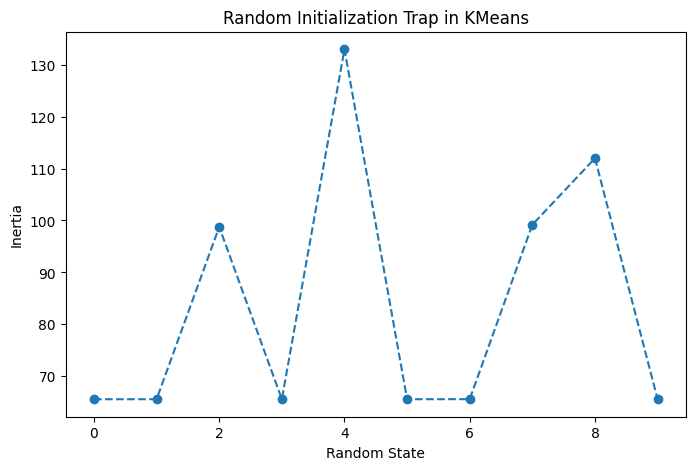

In [24]:
    # visualize
plt.figure(figsize=(8,5))
plt.plot(range(10),inertia_values, marker="o", linestyle="--")

plt.xlabel("Random State")
plt.ylabel("Inertia")
plt.title("Random Initialization Trap in KMeans")
plt.show()

In [28]:
# Use the Elbow Method to determine the optimal number of clusters

inertia=[]

K=range(1,11)

for k in K:
  kmeans=KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)
print(inertia)

[399.99999999999994, 269.69101219276405, 157.70400815035939, 108.92131661364358, 65.56840815571681, 55.057348270385965, 44.86475569922555, 37.22818767758587, 32.39226763033118, 29.981897788243703]


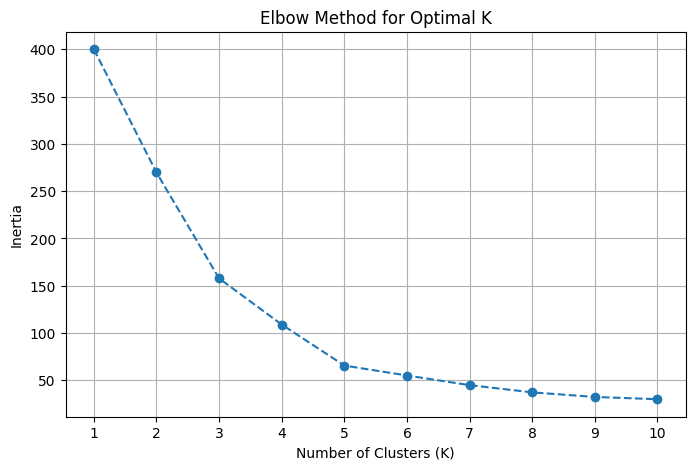

In [34]:
      # visualize

plt.figure(figsize=(8,5))
plt.plot(K,inertia,marker="o",linestyle="--")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(K)
plt.grid(True)   # show graph format

plt.show()

In [35]:
# Build the final K-Means model

final_kmeans=KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"]=final_kmeans.fit_predict(X_scaled)
df

,CustomerID,Genre,Age,Annual_Income,Spending_Score,Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
...,...,...,...,...,...,...
195,196,Female,35,120,79,1
196,197,Female,45,126,28,3
197,198,Male,32,126,74,1
198,199,Male,32,137,18,3


In [38]:
df["Cluster"].value_counts().sort_index()           #  81+39+22+35+23=200

,count
Cluster,
0,81
1,39
2,22
3,35
4,23


In [41]:
print(df.columns.tolist())
print(X.columns.tolist())

['CustomerID', 'Genre', 'Age', 'Annual_Income', 'Spending_Score', 'Cluster']
['Annual_Income', 'Spending_Score']


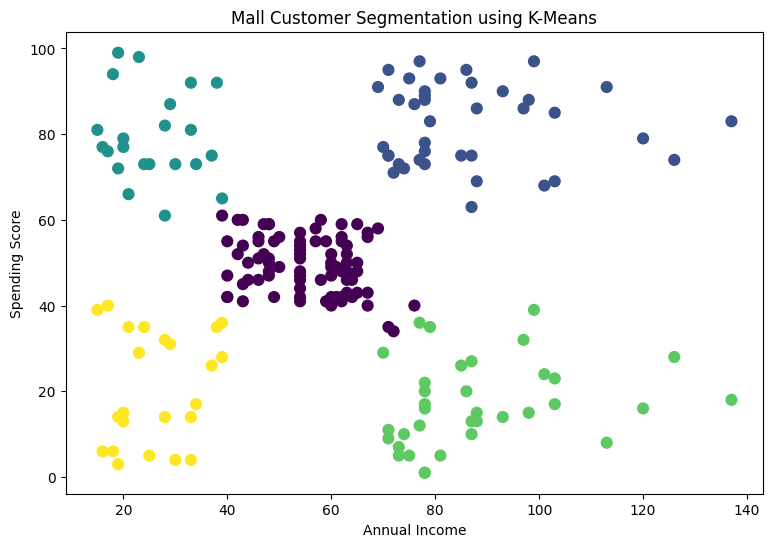

In [43]:
    # visualize

plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual_Income'],
    X['Spending_Score'],
    c=df['Cluster'],
    cmap='viridis',
    s=60
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Mall Customer Segmentation using K-Means")

plt.show()

In [59]:
       # Evaluate

from sklearn.metrics import silhouette_score

k_score=silhouette_score(X_scaled, df["Cluster"])

print(round(k_score,4))          # near1=good,near0=overlap, under0=wrong place in datapoints

0.5547


**Task 3** – Hierarchical Clustering

● Generate a Dendrogram

● Apply Agglomerative Hierarchical Clustering

● Compare cluster formation with K-Means

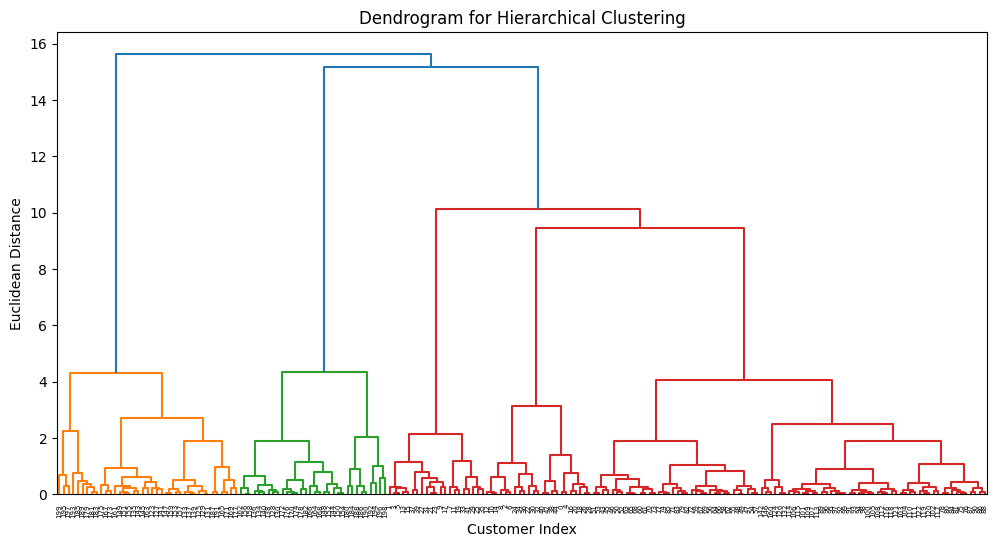

In [46]:
# Generate a Dendrogram

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

# Create linkage matrix
linked = linkage(X_scaled, method='ward')

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Euclidean Distance")

plt.show()

In [51]:
# Apply Agglomerative Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(n_clusters=5, linkage='ward')   # no need(n_init,random state)

df["hierarchical_clustering"]=hierarchical.fit_predict(X_scaled)

print(df["hierarchical_clustering"].value_counts().sort_index())    # 32+39+85+21+23=200

hierarchical_clustering
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


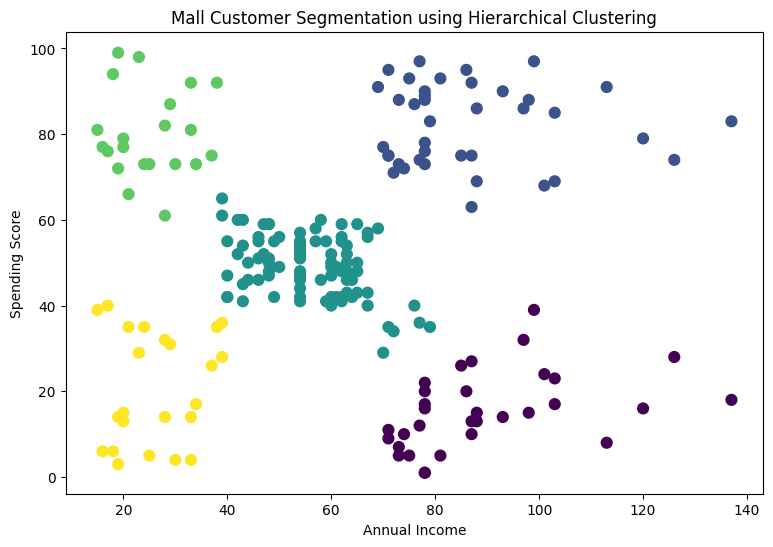

In [55]:
    # visualize

plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual_Income'],
    X['Spending_Score'],
    c=df['hierarchical_clustering'],
    cmap='viridis',
    s=60
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Mall Customer Segmentation using Hierarchical Clustering")

plt.show()

In [58]:
# Evaluate

from sklearn.metrics import silhouette_score

hier_score=silhouette_score(X_scaled, df["hierarchical_clustering"])

print(round(hier_score,4))          # near1=good,near0=overlap, under0=wrong place in datapoints

0.5538


In [57]:
# Compare cluster formation with K-Means

print(df["Cluster"].value_counts().sort_index())
print(df["hierarchical_clustering"].value_counts().sort_index())

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
hierarchical_clustering
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


In [61]:
      # silhouette_score comparison
print(round(k_score,4))      # it is high. so it is the best.
print(round(hier_score,4))

0.5547
0.5538


**Task 4** – DBSCAN Clustering

● Apply DBSCAN clustering

● Identify clusters and noise points

● Compare DBSCAN results with K-Means and Hierarchical Clustering

In [64]:
# Apply DBSCAN clustering

from sklearn.cluster import DBSCAN      # -1 = noise points , other = normal

# Apply DBSCAN
dbscan = DBSCAN(eps=0.3, min_samples=5)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64


In [65]:
# Identify clusters and noise points


# Count clusters, excluding noise
n_clusters = len(set(df['DBSCAN_Cluster'])) - (
    1 if -1 in df['DBSCAN_Cluster'].values else 0
)

# Count noise points
n_noise = (df['DBSCAN_Cluster'] == -1).sum()

print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

Number of Clusters: 7
Number of Noise Points: 35


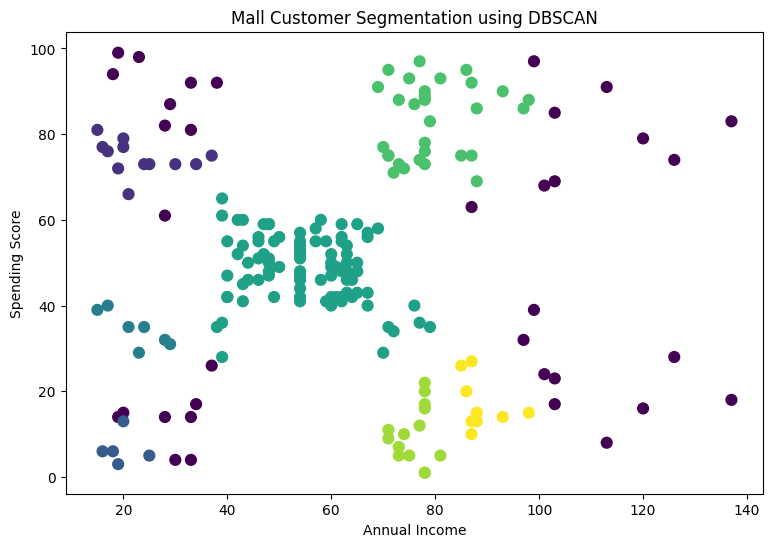

In [66]:
    # visualize
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual_Income'],
    X['Spending_Score'],
    c=df['DBSCAN_Cluster'],
    cmap='viridis',
    s=60
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Mall Customer Segmentation using DBSCAN")
plt.show()

In [67]:
# Compare DBSCAN results with K-Means and Hierarchical Clustering


from sklearn.metrics import silhouette_score

# Remove noise points
data = X_scaled[df['DBSCAN_Cluster'] != -1]
labels = df.loc[df['DBSCAN_Cluster'] != -1, 'DBSCAN_Cluster']

# Calculate Silhouette Score
if len(labels.unique()) > 1:
    score = silhouette_score(data, labels)
    print("DBSCAN Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score cannot be calculated")


DBSCAN Silhouette Score: 0.5243


In [69]:
    # comparision( Kmeans is high score. so that is the best model)

print("K-Means Silhouette Score:", round(k_score, 4))
print("Hierarchical Clustering Silhouette Score:", round(hier_score, 4))
print("DBSCAN Silhouette Score:", round(score, 4))

K-Means Silhouette Score: 0.5547
Hierarchical Clustering Silhouette Score: 0.5538
DBSCAN Silhouette Score: 0.5243


**Task 5** – Dimensionality Reduction

● Apply PCA to reduce dimensionality

● Apply t-SNE for low-dimensional representation

● Compare insights obtained from PCA and t-SNE

In [70]:
# Apply PCA to reduce dimensionality

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("PCA Shape:", X_pca.shape)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", pca.explained_variance_ratio_.sum())

Original Shape: (200, 2)
PCA Shape: (200, 2)
Explained Variance Ratio: [0.50495142 0.49504858]
Total Explained Variance: 1.0


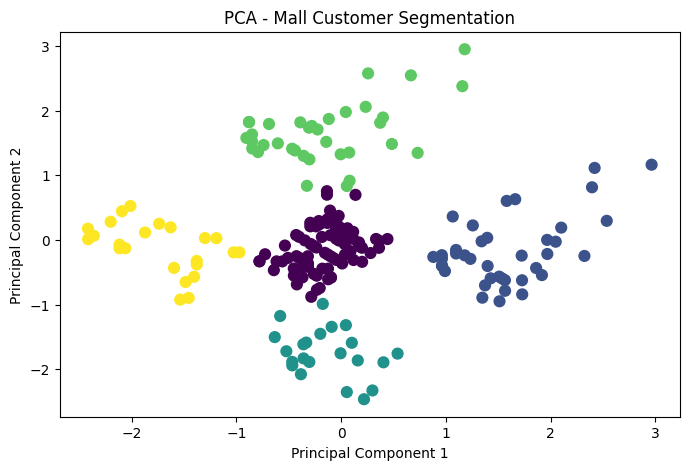

In [71]:
    # visualize

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],    # color base
    cmap='viridis',
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Mall Customer Segmentation")

plt.show()

In [72]:
# Apply t-SNE for low-dimensional representation

from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

X_tsne = tsne.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("t-SNE Shape:", X_tsne.shape)

Original Shape: (200, 2)
t-SNE Shape: (200, 2)


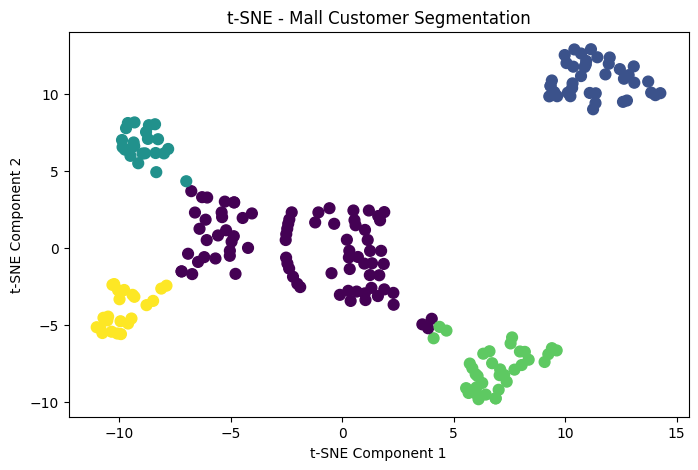

In [73]:
    # visualize

plt.figure(figsize=(8, 5))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=60
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE - Mall Customer Segmentation")

plt.show()

**Comparison of PCA and t-SNE**

PCA helps to understand the important information in the dataset. In my project, PCA explained 100% of the variance using two components.

t-SNE helps to visualize similar customers and understand their patterns using a graph.

Both methods helped me understand customer data in different ways.


**Task 6** – Cluster Analysis

● Analyze customer characteristics within each cluster

● Identify meaningful customer segments

● Provide business recommendations based on the clusters

In [74]:
# Analyze customer characteristics within each cluster

df.groupby('Cluster')[['Annual_Income', 'Spending_Score']].mean().round(2)

,Annual_Income,Spending_Score
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


### **Cluster Analysis**

I analyzed the customers using Annual Income and Spending Score.

* **Cluster 0:** Average income and average spending.
* **Cluster 1:** High income and high spending.
* **Cluster 2:** Low income and high spending.
* **Cluster 3:** High income and low spending.
* **Cluster 4:** Low income and low spending.



### **Business Recommendations**

The mall can give rewards to high-income, high-spending customers. It can provide discounts and budget-friendly products to low-income customers. Personalized offers can encourage high-income, low-spending customers to spend more. Seasonal offers can attract average customers.

These ideas can help increase customer satisfaction and sales.


# **Thank you**